In [55]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

In [56]:
df=pd.read_csv('salaries.csv')
df.head(2)

,company,job,degree,salary_more_than_100k
0,google,sales executive,bachelors,0
1,google,sales executive,masters,0


In [57]:
comp=LabelEncoder()
jo=LabelEncoder()
deg=LabelEncoder()

In [58]:
df['company']=comp.fit_transform(df['company'])
df['job']=jo.fit_transform(df['job'])
df['degree']=deg.fit_transform(df['degree'])

In [59]:
x=df[['company','job','degree']]
y=df['salary_more_than_100k']

In [60]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [61]:
model=DecisionTreeClassifier(criterion='entropy',random_state=42)
model.fit(x_train,y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


[Text(0.4444444444444444, 0.875, 'company <= 0.5\nentropy = 0.918\nsamples = 12\nvalue = [4, 8]\nclass = yes'), Text(0.2222222222222222, 0.625, 'degree <= 0.5\nentropy = 0.811\nsamples = 4\nvalue = [3, 1]\nclass = no'), Text(0.3333333333333333, 0.75, 'True  '), Text(0.1111111111111111, 0.375, 'entropy = 0.0\nsamples = 2\nvalue = [2, 0]\nclass = no'), Text(0.3333333333333333, 0.375, 'job <= 1.0\nentropy = 1.0\nsamples = 2\nvalue = [1, 1]\nclass = no'), Text(0.2222222222222222, 0.125, 'entropy = 0.0\nsamples = 1\nvalue = [0, 1]\nclass = yes'), Text(0.4444444444444444, 0.125, 'entropy = 0.0\nsamples = 1\nvalue = [1, 0]\nclass = no'), Text(0.6666666666666666, 0.625, 'company <= 1.5\nentropy = 0.544\nsamples = 8\nvalue = [1, 7]\nclass = yes'), Text(0.5555555555555556, 0.75, '  False'), Text(0.5555555555555556, 0.375, 'entropy = 0.0\nsamples = 5\nvalue = [0, 5]\nclass = yes'), Text(0.7777777777777778, 0.375, 'job <= 0.5\nentropy = 0.918\nsamples = 3\nvalue = [1, 2]\nclass = yes'), Text(0.666

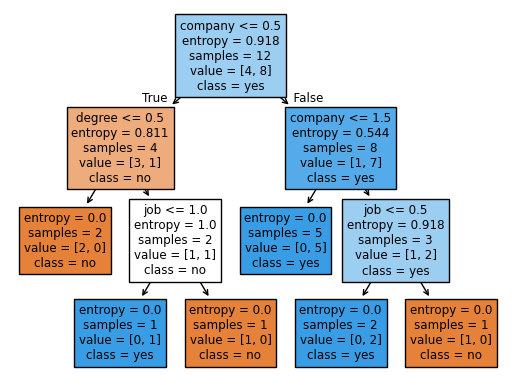

In [62]:
from sklearn import tree
print(tree.plot_tree(
    model,
    feature_names=['company','job','degree'],
    class_names=['no','yes'],
    filled=True
))

In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

In [64]:
y_pred=model.predict(x_test)
cm=confusion_matrix(y_test,y_pred)
cm

array([[2, 0],
       [1, 1]])

<Axes: >

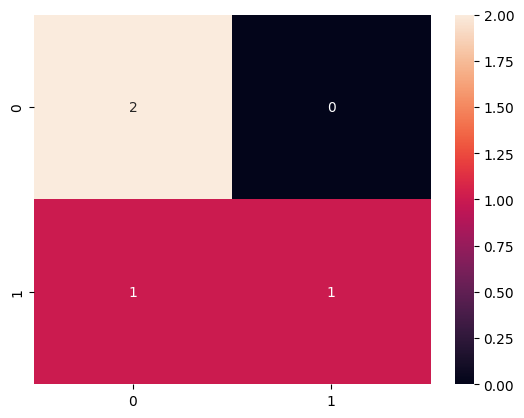

In [65]:
import seaborn as sns
sns.heatmap(
    cm,
    annot=True,
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

In [71]:
company = input("Enter company: ")
job = input("Enter job title: ")
degree = input("Enter degree: ")

new_sample = [[
    comp.transform([company])[0],
    jo.transform([job])[0],
    deg.transform([degree])[0]
]]

prediction = model.predict(new_sample)

print("Prediction:", prediction)

if prediction[0] == 1:
    print("Salary is more than 100K")
else:
    print("Salary is not more than 100K")

Prediction: [1]
Salary is more than 100K


c:\Users\VIVEK V\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [72]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.75